# Grokking and Fourier Circuits in Modular Arithmetic

A mechanistic interpretability study of one-layer transformers trained on modular addition and subtraction modulo 113. This project investigates how arithmetic structure emerges in learned embeddings, MLP activations, and output logits through Fourier analysis, frequency ablations, and trigonometric decomposition.

The addition experiments build on Nanda et al., *Progress measures for grokking via mechanistic interpretability* ([ICLR 2023](https://arxiv.org/abs/2301.05217)). The same analytical approach is applied to modular subtraction to examine the representations learned for a related arithmetic operation.

## Experimental setup

- **Tasks:** predict `(a + b) mod 113` and `(a - b) mod 113` from the input sequence `[a, b, =]`.
- **Dataset:** all 12,769 input pairs, split into 30% training and 70% test data.
- **Architecture:** one transformer layer, four attention heads, 128-dimensional embeddings, and a 512-unit ReLU MLP, with zeroed frozen biases and no layer normalization.
- **Training:** 25,000 full-batch updates per task using AdamW, a learning rate of 0.001, and weight decay of 1.0.
- **Analysis:** Fourier spectra, activation visualizations, frequency ablations, PCA, and trigonometric fits to subtraction activations and logits.

## Results

| Addition condition | Test accuracy |
|---|---:|
| Baseline | 100% |
| Remove frequencies 7, 15, and 19 | 0.88% |
| Keep only frequencies 7, 15, and 19, plus DC | 100% |

The subtraction model achieved **100% test accuracy**, with dominant embedding frequencies at **27 and 46**. A cosine-based approximation of its logits achieved **100% test accuracy** and explained **50.29% of logit variance**.

## Setup

Install the dependencies below and execute the cells in order. Training automatically uses CUDA when available. Checkpoints and figures are saved to the working directory.

## Dependencies


In [ ]:
%pip install torch transformer_lens==2.16.1 numpy scipy matplotlib scikit-learn seaborn tqdm


## 1. Modular addition: setup and training

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from transformer_lens import HookedTransformer, HookedTransformerConfig
from tqdm.notebook import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

torch.manual_seed(0)
np.random.seed(0)


Using device: cuda


In [ ]:
P = 113

x = torch.arange(P)
y = torch.arange(P)
x_grid, y_grid = torch.meshgrid(x, y, indexing='ij')

answers = (x_grid + y_grid) % P

# Token P represents '='.
equals_token = P
data = torch.stack([x_grid.flatten(), y_grid.flatten(), torch.full((P*P,), equals_token)], dim=1)
labels = answers.flatten()

data = data.to(device)
labels = labels.to(device)

total_samples = P * P
train_fraction = 0.3
num_train = int(total_samples * train_fraction)

indices = torch.randperm(total_samples)
train_indices = indices[:num_train]
test_indices = indices[num_train:]

train_data, train_labels = data[train_indices], labels[train_indices]
test_data, test_labels = data[test_indices], labels[test_indices]

print(f"Total samples: {total_samples}")
print(f"Training samples: {len(train_data)} ({len(train_data)/total_samples:.1%})")
print(f"Test samples: {len(test_data)}")


Total samples: 12769
Training samples: 3830 (30.0%)
Test samples: 8939


In [ ]:
cfg = HookedTransformerConfig(
    n_layers = 1,
    n_heads = 4,
    d_model = 128,
    d_head = 32,
    d_mlp = 512,
    act_fn = "relu",
    normalization_type = None,
    d_vocab = P + 1,
    d_vocab_out = P,
    n_ctx = 3,
    init_weights = True,
    device = device,
    seed = 999,
)

model = HookedTransformer(cfg)

for name, param in model.named_parameters():
    if "b_" in name:
        param.requires_grad = False
        param.data.fill_(0.0)

print("Model initialized. Biases frozen and zeroed.")


Model initialized. Biases frozen and zeroed.


In [ ]:
def loss_fn(logits, labels):

    last_token_logits = logits[:, -1, :]

    # Use float64 for stable log probabilities.
    last_token_logits = last_token_logits.to(torch.float64)

    log_probs = F.log_softmax(last_token_logits, dim=-1)

    label_log_probs = log_probs.gather(1, labels.unsqueeze(1))

    return -label_log_probs.mean()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-3,
    betas=(0.9, 0.98),
    weight_decay=1.0
)


In [ ]:
num_epochs = 25000
train_losses = []
test_losses = []
train_accs = []
test_accs = []

pbar = tqdm(range(num_epochs))

for epoch in pbar:

    model.train()
    logits = model(train_data)
    loss = loss_fn(logits, train_labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_loss_val = loss.item()

    with torch.no_grad():

        preds = logits[:, -1, :].argmax(dim=-1)
        train_acc_val = (preds == train_labels).float().mean().item()

    if epoch % 100 == 0 or epoch == num_epochs - 1:
        model.eval()
        with torch.no_grad():
            test_logits = model(test_data)
            test_loss_val = loss_fn(test_logits, test_labels).item()
            test_preds = test_logits[:, -1, :].argmax(dim=-1)
            test_acc_val = (test_preds == test_labels).float().mean().item()

        train_losses.append(train_loss_val)
        test_losses.append(test_loss_val)
        train_accs.append(train_acc_val)
        test_accs.append(test_acc_val)

        pbar.set_description(f"Epoch {epoch} | Train Loss: {train_loss_val:.4f} | Train Acc: {train_acc_val:.3f} | Test Acc: {test_acc_val:.3f}")


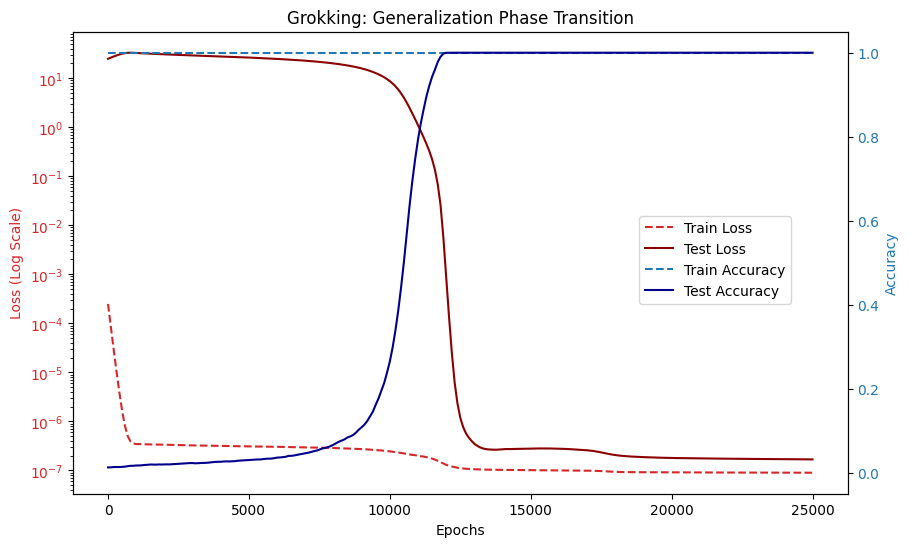

In [ ]:
steps = np.arange(0, num_epochs + 1, 100)

if len(steps) > len(train_losses): steps = steps[:len(train_losses)]

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss (Log Scale)', color='tab:red')
ax1.plot(steps, train_losses, color='tab:red', linestyle='--', label='Train Loss')
ax1.plot(steps, test_losses, color='darkred', label='Test Loss')
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.set_yscale('log')

ax2 = ax1.twinx()
ax2.set_ylabel('Accuracy', color='tab:blue')
ax2.plot(steps, train_accs, color='tab:blue', linestyle='--', label='Train Accuracy')
ax2.plot(steps, test_accs, color='darkblue', label='Test Accuracy')
ax2.tick_params(axis='y', labelcolor='tab:blue')
ax2.set_ylim(-0.05, 1.05)

plt.title('Grokking: Generalization Phase Transition')
fig.legend(loc="center right", bbox_to_anchor=(0.85, 0.5))
plt.show()

torch.save(model.state_dict(), 'model1_weights.pth')


## 2. Addition: embedding spectrum

Top detected frequencies: [7, 19, 15]


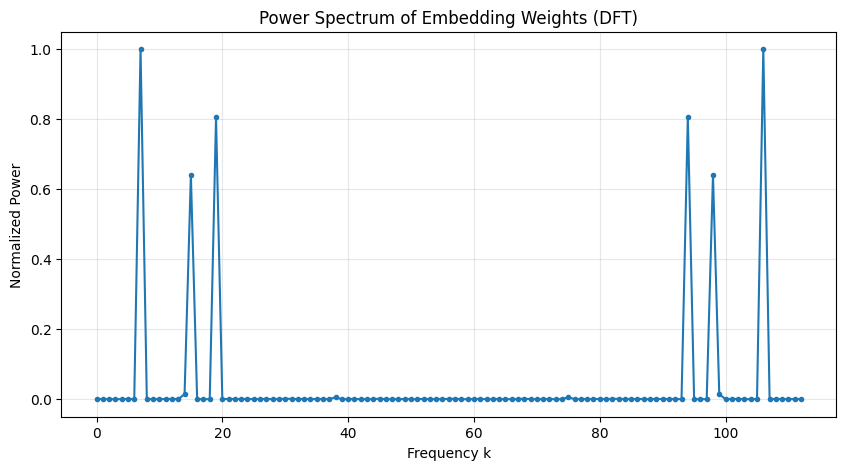

In [ ]:
import torch.fft

def analyze_embedding_periodicity(model):

    W_E = model.W_E[:P, :].detach().cpu()

    W_E_fft = torch.fft.fft(W_E, dim=0)

    fft_power = (W_E_fft.abs() ** 2).sum(dim=1)

    fft_power = fft_power / fft_power.max()

    plt.figure(figsize=(10, 5))
    plt.plot(torch.arange(P), fft_power, marker='o', markersize=3)
    plt.title('Power Spectrum of Embedding Weights (DFT)')
    plt.xlabel('Frequency k')
    plt.ylabel('Normalized Power')
    plt.grid(True, alpha=0.3)

    half_spectrum = fft_power[1 : P//2 + 1]
    top_k_indices = torch.topk(half_spectrum, k=3).indices + 1
    print(f"Top detected frequencies: {top_k_indices.tolist()}")

    return top_k_indices.tolist()

key_freqs = analyze_embedding_periodicity(model)


### Internal activations and attention

Visualize the highest-variance MLP neuron and an attention head across all input pairs to inspect periodic structure in the learned representations.


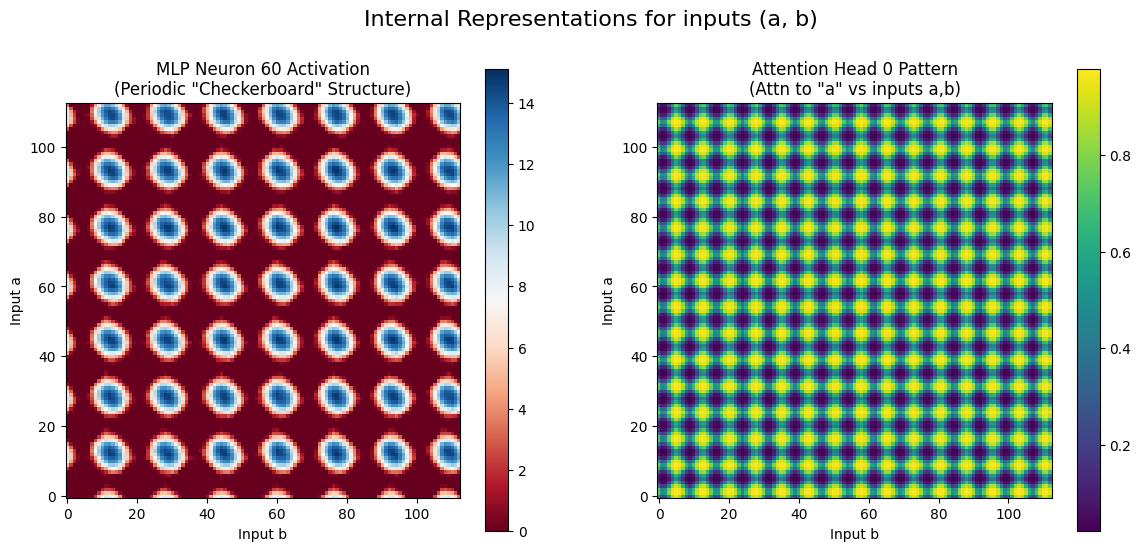

In [ ]:
def visualize_activations(model, key_freq):

    x = torch.arange(P)
    y = torch.arange(P)
    x_grid, y_grid = torch.meshgrid(x, y, indexing='ij')

    grid_input = torch.stack([
        x_grid.flatten(),
        y_grid.flatten(),
        torch.full((P*P,), P)
    ], dim=1).to(device)

    with torch.no_grad():
        logits, cache = model.run_with_cache(grid_input)

    mlp_acts = cache['post', 0][:, -1, :]

    neuron_idx = torch.argmax(mlp_acts.var(dim=0)).item()

    neuron_map = mlp_acts[:, neuron_idx].reshape(P, P).cpu()

    attn_patterns = cache['pattern', 0][:, :, -1, :]
    head_idx = 0

    attn_map = attn_patterns[:, head_idx, 0].reshape(P, P).cpu()

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    im1 = axes[0].imshow(neuron_map, cmap='RdBu', origin='lower')
    axes[0].set_title(f'MLP Neuron {neuron_idx} Activation\n(Periodic "Checkerboard" Structure)')
    axes[0].set_xlabel('Input b')
    axes[0].set_ylabel('Input a')
    fig.colorbar(im1, ax=axes[0])

    im2 = axes[1].imshow(attn_map, cmap='viridis', origin='lower')
    axes[1].set_title(f'Attention Head {head_idx} Pattern\n(Attn to "a" vs inputs a,b)')
    axes[1].set_xlabel('Input b')
    axes[1].set_ylabel('Input a')
    fig.colorbar(im2, ax=axes[1])

    plt.suptitle(f'Internal Representations for inputs (a, b)', fontsize=16)
    plt.show()

if len(key_freqs) > 0:
    visualize_activations(model, key_freqs[0])
else:
    print("No key frequencies found in Step 1 to analyze.")


### Logits and an illustrative cosine

Compare the model's output logits for a sample addition problem with a cosine at the dominant embedding frequency, centered on the correct answer.


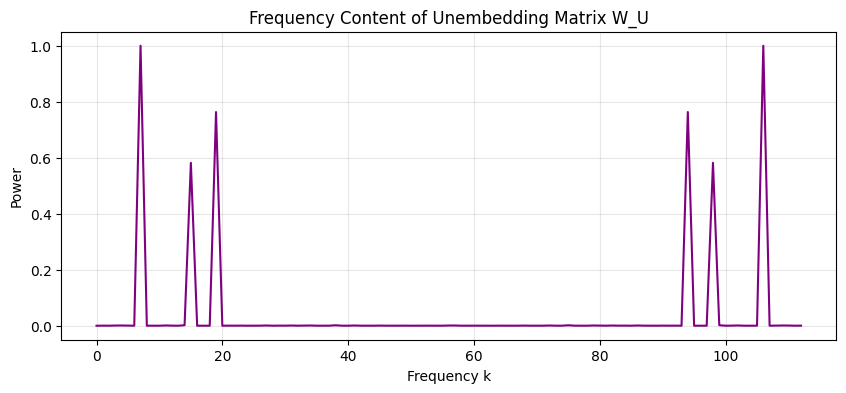


Demonstrating Constructive Interference for 15 + 20 = 35


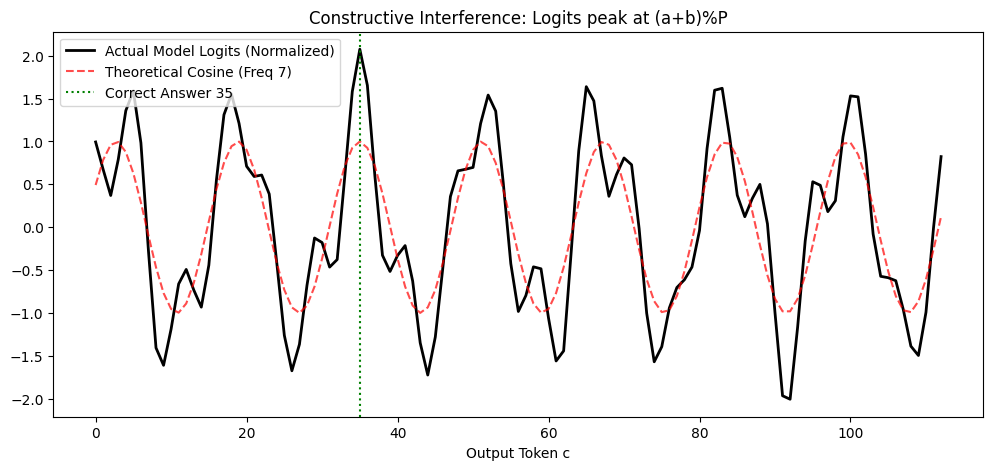

In [ ]:
def verify_constructive_interference(model, key_freqs):

    W_U = model.W_U[:, :P].detach().cpu()

    W_U_fft = torch.fft.fft(W_U, dim=1)

    wu_freq_power = (W_U_fft.abs() ** 2).sum(dim=0)
    wu_freq_power = wu_freq_power / wu_freq_power.max()

    plt.figure(figsize=(10, 4))
    plt.plot(torch.arange(P), wu_freq_power, color='purple')
    plt.title('Frequency Content of Unembedding Matrix W_U')
    plt.xlabel('Frequency k')
    plt.ylabel('Power')
    plt.grid(True, alpha=0.3)
    plt.show()

    a, b = 15, 20
    target = (a + b) % P

    print(f"\nDemonstrating Constructive Interference for {a} + {b} = {target}")

    if len(key_freqs) == 0: return
    omega = key_freqs[0]

    input_seq = torch.tensor([[a, b, P]]).to(device)
    with torch.no_grad():
        logits = model(input_seq)[0, -1, :P].cpu()

    x_range = torch.arange(P)

    theoretical_wave = torch.cos((2 * torch.pi * omega / P) * (x_range - target))

    fig, ax = plt.subplots(figsize=(12, 5))

    norm_logits = (logits - logits.mean()) / logits.std()
    ax.plot(x_range, norm_logits, label='Actual Model Logits (Normalized)', color='black', linewidth=2)

    ax.plot(x_range, theoretical_wave, label=f'Theoretical Cosine (Freq {omega})',
            linestyle='--', color='red', alpha=0.7)

    ax.axvline(target, color='green', linestyle=':', label=f'Correct Answer {target}')

    ax.set_title(f'Constructive Interference: Logits peak at (a+b)%P')
    ax.set_xlabel('Output Token c')
    ax.legend()
    plt.show()

verify_constructive_interference(model, key_freqs)


### Key frequencies in embeddings and the neuron–logit map

Apply a discrete Fourier transform to the embedding matrix and the neuron–logit map. Compare their dominant frequencies and quantify spectral concentration using the Gini coefficient.


In [ ]:
import torch
import numpy as np
from scipy.fft import fft
import matplotlib.pyplot as plt

def analyze_fourier_components(matrix, axis, name="Matrix"):
    """Compute cosine and sine component norms along the selected axis."""
    mat_np = matrix.detach().cpu().numpy()

    fft_result = fft(mat_np, axis=axis)

    cos_components = np.real(fft_result)
    sin_components = np.imag(fft_result)

    other_axis = 1 - axis
    cos_norms = np.linalg.norm(cos_components, axis=other_axis)
    sin_norms = np.linalg.norm(sin_components, axis=other_axis)

    n_freqs = len(cos_norms) // 2 + 1
    frequencies = np.arange(n_freqs)

    return frequencies, cos_norms[:n_freqs], sin_norms[:n_freqs]

def identify_key_frequencies(cos_norms, sin_norms, threshold_percentile=95, top_k=5):
    """Select nonzero frequencies by percentile and magnitude."""
    combined_norms = np.sqrt(cos_norms**2 + sin_norms**2)

    threshold = np.percentile(combined_norms[1:], threshold_percentile)
    key_freqs_threshold = np.where(combined_norms > threshold)[0]
    key_freqs_threshold = key_freqs_threshold[key_freqs_threshold > 0]

    top_k_indices = np.argsort(combined_norms[1:])[-top_k:][::-1] + 1

    return key_freqs_threshold.tolist(), top_k_indices.tolist(), combined_norms

def gini_coefficient(norms):
    """Measure concentration of nonnegative spectral magnitudes."""
    sorted_norms = np.sort(norms)
    n = len(sorted_norms)
    index = np.arange(1, n + 1)
    return (2 * np.sum(index * sorted_norms)) / (n * np.sum(sorted_norms)) - (n + 1) / n

print("=== Embedding Matrix W_E Analysis ===")
W_E = model.embed.W_E[:P, :]

freqs_embed, cos_norms_embed, sin_norms_embed = analyze_fourier_components(
    W_E, axis=0, name="W_E"
)

key_freqs_embed_threshold, top_5_embed, combined_norms_embed = identify_key_frequencies(
    cos_norms_embed, sin_norms_embed, top_k=5
)

print(f"Key frequencies from W_E (threshold-based): {key_freqs_embed_threshold}")
print(f"Top 5 frequencies from W_E by norm:")
for i, k in enumerate(top_5_embed, 1):
    print(f"  {i}. Frequency {k}: norm = {combined_norms_embed[k]:.4f}")

print("\n=== Neuron-Logit Map W_L Analysis ===")

W_out = model.blocks[0].mlp.W_out
W_U = model.unembed.W_U

W_L = (W_out @ W_U).T
print(f"W_L shape: {W_L.shape} = (P, d_mlp) = ({P}, {cfg.d_mlp})")

freqs_logit, cos_norms_logit, sin_norms_logit = analyze_fourier_components(
    W_L, axis=0, name="W_L"
)

key_freqs_logit_threshold, top_5_logit, combined_norms_logit = identify_key_frequencies(
    cos_norms_logit, sin_norms_logit, top_k=5
)

print(f"Key frequencies from W_L (threshold-based): {key_freqs_logit_threshold}")
print(f"Top 5 frequencies from W_L by norm:")
for i, k in enumerate(top_5_logit, 1):
    print(f"  {i}. Frequency {k}: norm = {combined_norms_logit[k]:.4f}")

consensus_freqs_threshold = sorted(set(key_freqs_embed_threshold) & set(key_freqs_logit_threshold))
consensus_freqs_top5 = sorted(set(top_5_embed) & set(top_5_logit))

print(f"\n=== Consensus Key Frequencies ===")
print(f"Appearing in both W_E and W_L (threshold-based): {consensus_freqs_threshold}")
print(f"Appearing in both top 5 lists: {consensus_freqs_top5}")

all_freqs_threshold = sorted(set(key_freqs_embed_threshold + key_freqs_logit_threshold))
all_freqs_top5 = sorted(set(top_5_embed + top_5_logit))

print(f"\nAll identified key frequencies (threshold): {all_freqs_threshold}")
print(f"All unique frequencies from top 5 lists: {all_freqs_top5}")

gini_embed = gini_coefficient(combined_norms_embed[1:])
gini_logit = gini_coefficient(combined_norms_logit[1:])

print(f"\nSparsity Measures:")
print(f"Gini(W_E): {gini_embed:.4f}")
print(f"Gini(W_L): {gini_logit:.4f}")
print("(Higher = more sparse = concentrated in fewer frequencies)")

key_frequencies = consensus_freqs_top5 if consensus_freqs_top5 else all_freqs_top5
print(f"\nUsing key frequencies for ablation: {key_frequencies}")


=== Embedding Matrix W_E Analysis ===
Key frequencies from W_E (threshold-based): [7, 15, 19]
Top 5 frequencies from W_E by norm:
  1. Frequency 7: norm = 55.8561
  2. Frequency 19: norm = 50.1406
  3. Frequency 15: norm = 44.7046
  4. Frequency 14: norm = 6.7586
  5. Frequency 38: norm = 4.1948



=== Neuron-Logit Map W_L Analysis ===
W_L shape: torch.Size([113, 512]) = (P, d_mlp) = (113, 512)
Key frequencies from W_L (threshold-based): [7, 15, 19]
Top 5 frequencies from W_L by norm:
  1. Frequency 7: norm = 309.4563
  2. Frequency 19: norm = 235.9625
  3. Frequency 15: norm = 178.1797
  4. Frequency 4: norm = 7.6520
  5. Frequency 34: norm = 7.0460



=== Consensus Key Frequencies ===
Appearing in both W_E and W_L (threshold-based): [7, 15, 19]
Appearing in both top 5 lists: [7, 15, 19]

All identified key frequencies (threshold): [7, 15, 19]
All unique frequencies from top 5 lists: [4, 7, 14, 15, 19, 34, 38]

Sparsity Measures:
Gini(W_E): 0.7515
Gini(W_L): 0.8784
(Higher = more sparse = concentrated in fewer frequencies)

Using key frequencies for ablation: [7, 15, 19]


### Fourier ablation

Measure how selectively removing or retaining dominant Fourier frequencies changes accuracy and cross-entropy loss. Each intervention modifies both the embedding matrix and the neuron–logit map, with the latter implemented through a pseudoinverse-based update to the unembedding matrix.


In [ ]:
import torch
import numpy as np
from scipy.fft import fft, ifft
import copy

def ablate_frequencies_in_matrix(matrix, frequencies_to_ablate, axis=0):
    """Remove selected Fourier components and their conjugates."""
    mat_np = matrix.detach().cpu().numpy()

    fft_result = fft(mat_np, axis=axis)

    # Remove conjugate pairs to preserve real-valued weights.
    for k in frequencies_to_ablate:
        if axis == 0:
            fft_result[k, :] = 0

            if k > 0:
                fft_result[-k, :] = 0
        else:
            fft_result[:, k] = 0
            if k > 0:
                fft_result[:, -k] = 0

    ablated = ifft(fft_result, axis=axis).real

    return torch.tensor(ablated, dtype=matrix.dtype, device=matrix.device)

def ablate_frequencies_keep_only(matrix, frequencies_to_keep, axis=0):
    """Retain selected Fourier components, their conjugates, and DC."""
    mat_np = matrix.detach().cpu().numpy()
    P_dim = mat_np.shape[axis]

    fft_result = fft(mat_np, axis=axis)

    mask = np.zeros_like(fft_result)

    # Retain conjugate pairs.
    for k in frequencies_to_keep:
        if axis == 0:
            mask[k, :] = 1
            if k > 0 and k < P_dim:
                mask[-k, :] = 1
        else:
            mask[:, k] = 1
            if k > 0 and k < P_dim:
                mask[:, -k] = 1

    # Preserve the DC component.
    if axis == 0:
        mask[0, :] = 1
    else:
        mask[:, 0] = 1

    fft_result = fft_result * mask

    ablated = ifft(fft_result, axis=axis).real

    return torch.tensor(ablated, dtype=matrix.dtype, device=matrix.device)

def evaluate_model_with_ablation(model, ablated_W_E, ablated_W_L, data, labels, device, batch_size=512):
    """Evaluate a model copy with filtered embeddings and output mapping."""

    model_copy = copy.deepcopy(model)

    with torch.no_grad():

        new_W_E = model_copy.embed.W_E.clone()
        new_W_E[:P, :] = ablated_W_E
        model_copy.embed.W_E = torch.nn.Parameter(new_W_E)

    # Recover an unembedding from the filtered neuron–logit map.
    W_out = model.blocks[0].mlp.W_out
    W_out_pinv = torch.linalg.pinv(W_out)
    W_U_new = W_out_pinv @ ablated_W_L.T

    with torch.no_grad():
        model_copy.unembed.W_U = torch.nn.Parameter(W_U_new)

    model_copy.eval()
    correct = 0
    total = 0
    total_loss = 0.0

    num_samples = len(data)
    num_batches = (num_samples + batch_size - 1) // batch_size

    with torch.no_grad():
        for i in range(num_batches):
            start_idx = i * batch_size
            end_idx = min((i + 1) * batch_size, num_samples)

            batch_data = data[start_idx:end_idx]
            batch_labels = labels[start_idx:end_idx]

            logits = model_copy(batch_data)[:, 2, :]

            preds = logits.argmax(dim=-1)

            correct += (preds == batch_labels).sum().item()
            total += len(batch_data)

            loss = torch.nn.functional.cross_entropy(logits, batch_labels)
            total_loss += loss.item() * len(batch_data)

    accuracy = correct / total
    avg_loss = total_loss / total

    return accuracy, avg_loss

print("="*70)
print("FOURIER ABLATION EXPERIMENTS")
print("="*70)

key_frequencies = [7, 15, 19]
print(f"\nIdentified key frequencies: {key_frequencies}")

W_E_original = model.embed.W_E[:P, :].clone().detach()
W_out = model.blocks[0].mlp.W_out.detach()
W_U = model.unembed.W_U.detach()
W_L_original = (W_out @ W_U).T

print("\n" + "="*70)
print("BASELINE (No Ablation)")
print("="*70)

print("\nTrain Set:")
train_acc_baseline, train_loss_baseline = evaluate_model_with_ablation(
    model, W_E_original, W_L_original, train_data, train_labels, device
)
print(f"  Accuracy: {train_acc_baseline:.4f}")
print(f"  Loss: {train_loss_baseline:.6f}")

print("\nTest Set:")
test_acc_baseline, test_loss_baseline = evaluate_model_with_ablation(
    model, W_E_original, W_L_original, test_data, test_labels, device
)
print(f"  Accuracy: {test_acc_baseline:.4f}")
print(f"  Loss: {test_loss_baseline:.6f}")

print("\n" + "="*70)
print("EXPERIMENT 1: Ablate ALL Key Frequencies")
print("="*70)

W_E_ablated = ablate_frequencies_in_matrix(W_E_original, key_frequencies, axis=0)
W_L_ablated = ablate_frequencies_in_matrix(W_L_original, key_frequencies, axis=0)

print("\nTrain Set:")
train_acc_ablated, train_loss_ablated = evaluate_model_with_ablation(
    model, W_E_ablated, W_L_ablated, train_data, train_labels, device
)
print(f"  Accuracy: {train_acc_ablated:.4f}")
print(f"  Loss: {train_loss_ablated:.6f}")
print(f"  Change from baseline: Acc {train_acc_ablated - train_acc_baseline:+.4f}, Loss {train_loss_ablated - train_loss_baseline:+.6f}")

print("\nTest Set:")
test_acc_ablated, test_loss_ablated = evaluate_model_with_ablation(
    model, W_E_ablated, W_L_ablated, test_data, test_labels, device
)
print(f"  Accuracy: {test_acc_ablated:.4f}")
print(f"  Loss: {test_loss_ablated:.6f}")
print(f"  Change from baseline: Acc {test_acc_ablated - test_acc_baseline:+.4f}, Loss {test_loss_ablated - test_loss_baseline:+.6f}")

print("\n" + "="*70)
print("EXPERIMENT 2: Keep ONLY Key Frequencies (Restricted Loss)")
print("="*70)

W_E_restricted = ablate_frequencies_keep_only(W_E_original, key_frequencies, axis=0)
W_L_restricted = ablate_frequencies_keep_only(W_L_original, key_frequencies, axis=0)

n_total_freqs = P // 2 + 1
n_kept = len(key_frequencies) + 1
pct_kept = 100 * n_kept / n_total_freqs

print(f"Frequencies kept: {n_kept}/{n_total_freqs} ({pct_kept:.1f}%)")
print(f"Frequencies ablated: {n_total_freqs - n_kept}/{n_total_freqs} ({100-pct_kept:.1f}%)")

print("\nTrain Set:")
train_acc_restricted, train_loss_restricted = evaluate_model_with_ablation(
    model, W_E_restricted, W_L_restricted, train_data, train_labels, device
)
print(f"  Accuracy: {train_acc_restricted:.4f}")
print(f"  Loss: {train_loss_restricted:.6f}")
print(f"  Change from baseline: Acc {train_acc_restricted - train_acc_baseline:+.4f}, Loss {train_loss_restricted - train_loss_baseline:+.6f}")

print("\nTest Set:")
test_acc_restricted, test_loss_restricted = evaluate_model_with_ablation(
    model, W_E_restricted, W_L_restricted, test_data, test_labels, device
)
print(f"  Accuracy: {test_acc_restricted:.4f}")
print(f"  Loss: {test_loss_restricted:.6f}")
print(f"  Change from baseline: Acc {test_acc_restricted - test_acc_baseline:+.4f}, Loss {test_loss_restricted - test_loss_baseline:+.6f}")

print("\n" + "="*70)
print("SUMMARY - TRAIN SET")
print("="*70)
print(f"{'Condition':<35} {'Accuracy':<12} {'Loss':<12}")
print("-"*70)
print(f"{'Baseline (No Ablation)':<35} {train_acc_baseline:<12.4f} {train_loss_baseline:<12.6f}")
print(f"{'Ablate Key Frequencies':<35} {train_acc_ablated:<12.4f} {train_loss_ablated:<12.6f}")
print(f"{'Keep Only Key Frequencies':<35} {train_acc_restricted:<12.4f} {train_loss_restricted:<12.6f}")

print("\n" + "="*70)
print("SUMMARY - TEST SET")
print("="*70)
print(f"{'Condition':<35} {'Accuracy':<12} {'Loss':<12}")
print("-"*70)
print(f"{'Baseline (No Ablation)':<35} {test_acc_baseline:<12.4f} {test_loss_baseline:<12.6f}")
print(f"{'Ablate Key Frequencies':<35} {test_acc_ablated:<12.4f} {test_loss_ablated:<12.6f}")
print(f"{'Keep Only Key Frequencies':<35} {test_acc_restricted:<12.4f} {test_loss_restricted:<12.6f}")
print("="*70)


FOURIER ABLATION EXPERIMENTS

Identified key frequencies: [7, 15, 19]

BASELINE (No Ablation)

Train Set:
  Accuracy: 1.0000
  Loss: 0.000000

Test Set:
  Accuracy: 1.0000
  Loss: 0.000000

EXPERIMENT 1: Ablate ALL Key Frequencies

Train Set:
  Accuracy: 0.0089
  Loss: 5.527035
  Change from baseline: Acc -0.9911, Loss +5.527035

Test Set:
  Accuracy: 0.0088
  Loss: 5.486243
  Change from baseline: Acc -0.9912, Loss +5.486242

EXPERIMENT 2: Keep ONLY Key Frequencies (Restricted Loss)
Frequencies kept: 4/57 (7.0%)
Frequencies ablated: 53/57 (93.0%)

Train Set:
  Accuracy: 1.0000
  Loss: 0.000005
  Change from baseline: Acc +0.0000, Loss +0.000005

Test Set:
  Accuracy: 1.0000
  Loss: 0.000007
  Change from baseline: Acc +0.0000, Loss +0.000007

SUMMARY - TRAIN SET
Condition                           Accuracy     Loss        
----------------------------------------------------------------------
Baseline (No Ablation)              1.0000       0.000000    
Ablate Key Frequencies         

### Geometry of addition embeddings

Project the learned embeddings onto their first two principal components and visualize their circular geometry. Report explained variance and radial statistics to characterize the projection.


Moving model to device:  cuda
✓ Model object re-initialized from scratch.
Loading weights from: /content/model1_weights.pth
✓ Weights loaded successfully.
PCA VISUALIZATION OF EMBEDDING MATRIX

Embedding matrix shape: (113, 128)
Reducing from 128 dimensions to 2 dimensions using PCA
Explained variance ratio: [0.20530312 0.1972489 ]
Total variance explained: 40.26%

✓ Figure saved as: pca_embedding_circular_geometry.png


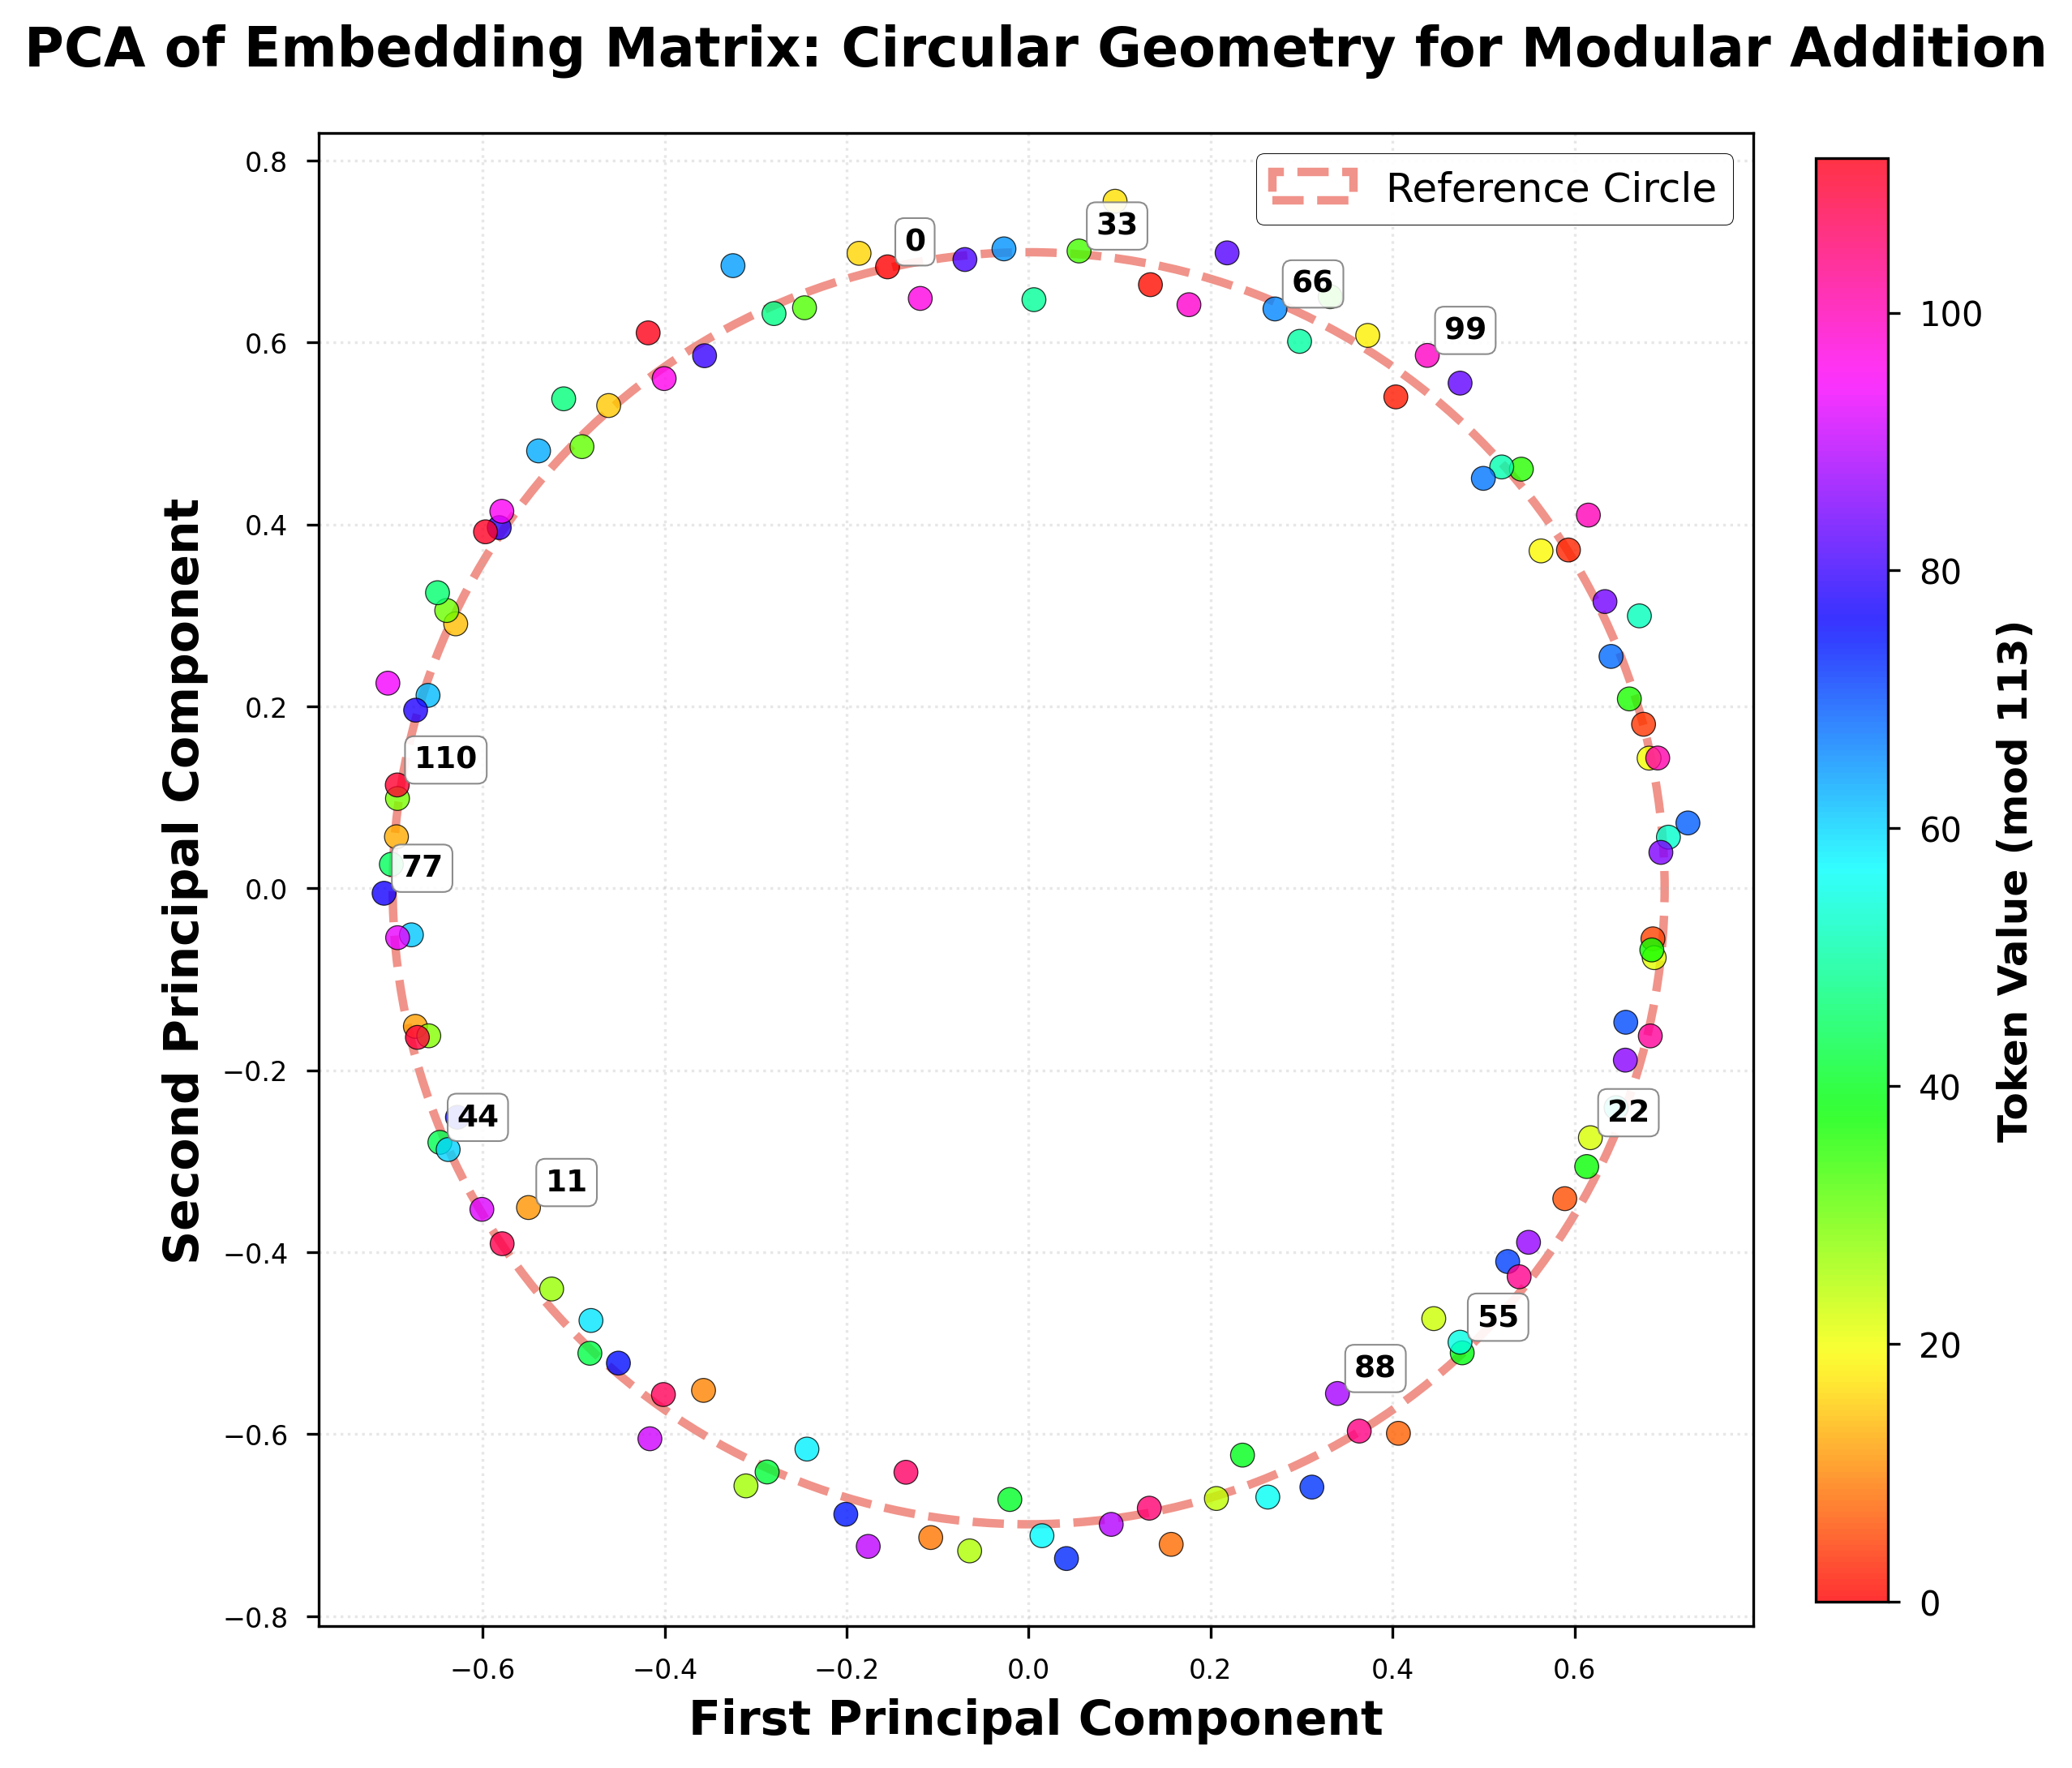


QUANTITATIVE ANALYSIS

Circularity metric: 0.9659
  (1.0 = perfect circle, 0.0 = not circular)
Mean radius: 0.6991
Std of radius: 0.0239
Coefficient of variation: 0.0341

✓ EXCELLENT: Points form a clear circle!
  Model has learned the rotational/Fourier representation

ANGULAR ORDERING ANALYSIS

Angular correlation with token order: 0.0120
  (1.0 = perfect ordering, -1.0 = reverse ordering)

✗ POOR: No clear angular ordering

SUMMARY STATISTICS (for paper reporting)
PCA explained variance: 40.26%
Circularity: 0.966
Angular correlation: 0.012
Radius CV: 0.034


In [ ]:
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import torch

try:
    model = HookedTransformer(cfg).to(device)
    print("✓ Model object re-initialized from scratch.")
except NameError:
    print("! Could not re-init model (class not found). Using existing 'model' object.")

path = 'model1_weights.pth'
print(f"Loading weights from: {path}")

try:
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint)
    model.eval()
    print("✓ Weights loaded successfully.")
except Exception as e:
    raise RuntimeError(f"Could not load checkpoint: {path}") from e

print("=" * 70)
print("PCA VISUALIZATION OF EMBEDDING MATRIX")
print("=" * 70)

W_E = model.embed.W_E[:P, :].detach().cpu().numpy()

print(f"\nEmbedding matrix shape: {W_E.shape}")
print(f"Reducing from {W_E.shape[1]} dimensions to 2 dimensions using PCA")

pca = PCA(n_components=2)
W_E_2d = pca.fit_transform(W_E)

print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum():.2%}")

plt.style.use('seaborn-v0_8-paper')
fig, ax = plt.subplots(figsize=(8, 8), dpi=300)

center = W_E_2d.mean(axis=0)
distances = np.sqrt(((W_E_2d - center) ** 2).sum(axis=1))
mean_radius = distances.mean()

circle = plt.Circle(center, mean_radius, fill=False, color='#E74C3C',
                   linestyle='--', linewidth=2.5, alpha=0.6, label='Reference Circle', zorder=1)
ax.add_patch(circle)

colors = np.arange(P)
scatter = ax.scatter(W_E_2d[:, 0], W_E_2d[:, 1],
                     c=colors,
                     cmap='hsv',
                     s=50,
                     alpha=0.8,
                     edgecolors='black',
                     linewidth=0.3,
                     zorder=2)

step = P // 10
for i in range(0, P, step):
    ax.annotate(f'{i}',
                xy=(W_E_2d[i, 0], W_E_2d[i, 1]),
                xytext=(5, 5),
                textcoords='offset points',
                fontsize=9,
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                         edgecolor='gray', alpha=0.9, linewidth=0.5),
                zorder=3)

ax.set_xlabel('First Principal Component', fontsize=14, fontweight='bold')
ax.set_ylabel('Second Principal Component', fontsize=14, fontweight='bold')
ax.set_title('PCA of Embedding Matrix: Circular Geometry for Modular Addition',
            fontsize=16, fontweight='bold', pad=20)

ax.set_aspect('equal', adjustable='box')

ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.8)

ax.legend(loc='upper right', fontsize=12, framealpha=0.95, edgecolor='black')

cbar = plt.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Token Value (mod 113)', fontsize=12, fontweight='bold')
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

output_filename = 'pca_embedding_circular_geometry.png'
plt.savefig(output_filename, dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')
print(f"\n✓ Figure saved as: {output_filename}")

plt.show()

print("\n" + "=" * 70)
print("QUANTITATIVE ANALYSIS")
print("=" * 70)

std_radius = distances.std()
circularity = 1 - (std_radius / mean_radius)

print(f"\nCircularity metric: {circularity:.4f}")
print(f"  (1.0 = perfect circle, 0.0 = not circular)")
print(f"Mean radius: {mean_radius:.4f}")
print(f"Std of radius: {std_radius:.4f}")
print(f"Coefficient of variation: {std_radius/mean_radius:.4f}")

if circularity > 0.9:
    print("\n✓ EXCELLENT: Points form a clear circle!")
    print("  Model has learned the rotational/Fourier representation")
elif circularity > 0.7:
    print("\n~ MODERATE: Points somewhat circular")
    print("  Model partially learned rotational structure")
else:
    print("\n✗ POOR: Points do NOT form a circle")
    print("  Model may not be using Fourier multiplication algorithm")

print("\n" + "=" * 70)
print("ANGULAR ORDERING ANALYSIS")
print("=" * 70)

angles = np.arctan2(W_E_2d[:, 1] - center[1], W_E_2d[:, 0] - center[0])
angles = (angles + 2 * np.pi) % (2 * np.pi)

sorted_indices = np.argsort(angles)
angular_correlation = np.corrcoef(sorted_indices, np.arange(P))[0, 1]

print(f"\nAngular correlation with token order: {angular_correlation:.4f}")
print(f"  (1.0 = perfect ordering, -1.0 = reverse ordering)")

if abs(angular_correlation) > 0.95:
    print("\n✓ EXCELLENT: Tokens are arranged in order around the circle!")
    print("  This confirms the rotational representation for modular arithmetic")
elif abs(angular_correlation) > 0.8:
    print("\n~ MODERATE: Tokens somewhat ordered around circle")
else:
    print("\n✗ POOR: No clear angular ordering")

print("\n" + "=" * 70)
print("SUMMARY STATISTICS (for paper reporting)")
print("=" * 70)
print(f"PCA explained variance: {pca.explained_variance_ratio_.sum()*100:.2f}%")
print(f"Circularity: {circularity:.3f}")
print(f"Angular correlation: {angular_correlation:.3f}")
print(f"Radius CV: {std_radius/mean_radius:.3f}")
print("=" * 70)


## 3. Modular subtraction: training

Using device: cuda
Task: Modular Subtraction (a - b mod 113)
Total samples: 12769
Training samples: 3830 (30.0%)
Test samples: 8939

Sample ground truth:
  0 - 0 ≡ 0 (mod 113)
  0 - 1 ≡ 112 (mod 113)
  0 - 2 ≡ 111 (mod 113)
  0 - 3 ≡ 110 (mod 113)
  0 - 4 ≡ 109 (mod 113)
Model initialized for SUBTRACTION task.
Biases frozen and zeroed.
Optimizer configured: AdamW with lr=1e-3, weight_decay=1.0

Starting training for 25000 epochs...
Monitoring every 100 epochs


Epoch 24999 | Train Loss: 0.0000 | Train Acc: 1.000 | Test Acc: 1.000: 100%|██████████| 25000/25000 [04:38<00:00, 89.89it/s]



✓ Training complete!
Model saved to: model_subtraction_weights.pth


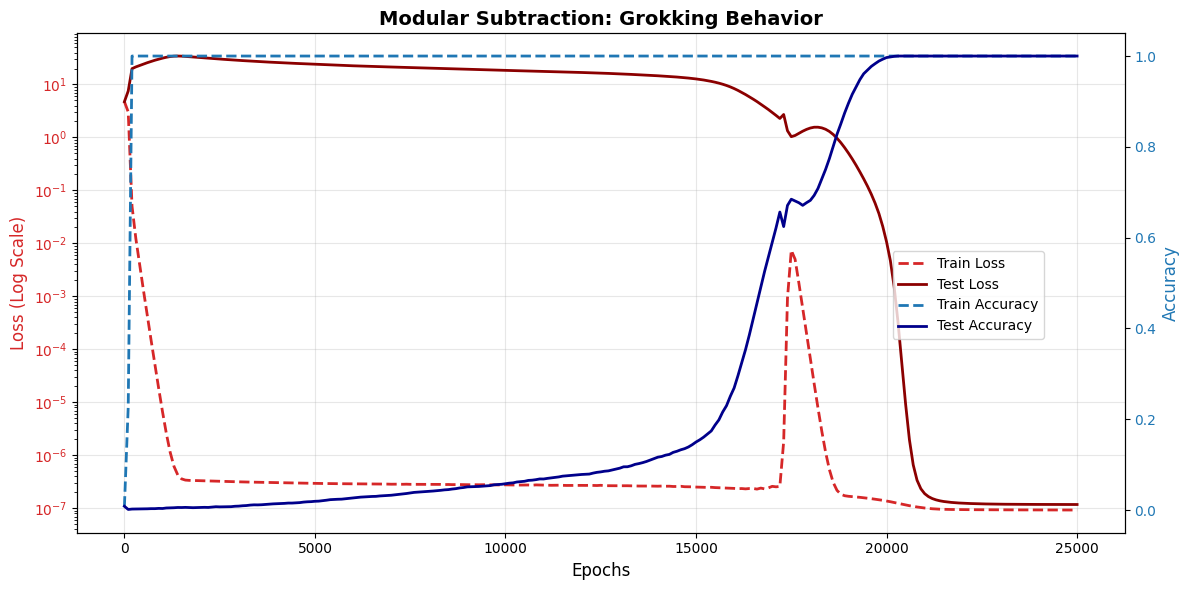


FINAL PERFORMANCE SUMMARY
Task: a - b ≡ c (mod 113)
Final Train Accuracy: 1.0000
Final Test Accuracy: 1.0000
Final Train Loss: 0.000000
Final Test Loss: 0.000000


In [ ]:
import torch
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from transformer_lens import HookedTransformer, HookedTransformerConfig

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

P = 113

x = torch.arange(P)
y = torch.arange(P)
x_grid, y_grid = torch.meshgrid(x, y, indexing='ij')

answers = (x_grid - y_grid) % P

# Token P represents '='.
equals_token = P
data = torch.stack([x_grid.flatten(), y_grid.flatten(), torch.full((P*P,), equals_token)], dim=1)
labels = answers.flatten()

data = data.to(device)
labels = labels.to(device)

total_samples = P * P
train_fraction = 0.3
num_train = int(total_samples * train_fraction)

indices = torch.randperm(total_samples)
train_indices = indices[:num_train]
test_indices = indices[num_train:]

train_data, train_labels = data[train_indices], labels[train_indices]
test_data, test_labels = data[test_indices], labels[test_indices]

print(f"Task: Modular Subtraction (a - b mod {P})")
print(f"Total samples: {total_samples}")
print(f"Training samples: {len(train_data)} ({len(train_data)/total_samples:.1%})")
print(f"Test samples: {len(test_data)}")

print("\nSample ground truth:")
for i in range(5):
    a, b = data[i, 0].item(), data[i, 1].item()
    c = labels[i].item()
    print(f"  {a} - {b} ≡ {c} (mod {P})")

cfg = HookedTransformerConfig(
    n_layers = 1,
    n_heads = 4,
    d_model = 128,
    d_head = 32,
    d_mlp = 512,
    act_fn = "relu",
    normalization_type = None,
    d_vocab = P + 1,
    d_vocab_out = P,
    n_ctx = 3,
    init_weights = True,
    device = device,
    seed = 999,
)

model_subtraction = HookedTransformer(cfg)

for name, param in model_subtraction.named_parameters():
    if "b_" in name:
        param.requires_grad = False
        param.data.fill_(0.0)

print("Model initialized for SUBTRACTION task.")
print("Biases frozen and zeroed.")

def loss_fn(logits, labels):
    """
    Custom loss function for numerical stability.
    """

    last_token_logits = logits[:, -1, :]

    # Use float64 for stable log probabilities.
    last_token_logits = last_token_logits.to(torch.float64)

    log_probs = F.log_softmax(last_token_logits, dim=-1)

    label_log_probs = log_probs.gather(1, labels.unsqueeze(1))

    return -label_log_probs.mean()

optimizer = optim.AdamW(
    model_subtraction.parameters(),
    lr=1e-3,
    betas=(0.9, 0.98),
    weight_decay=1.0
)

print("Optimizer configured: AdamW with lr=1e-3, weight_decay=1.0")

num_epochs = 25000
train_losses = []
test_losses = []
train_accs = []
test_accs = []

print(f"\nStarting training for {num_epochs} epochs...")
print("Monitoring every 100 epochs")
pbar = tqdm(range(num_epochs))

for epoch in pbar:

    model_subtraction.train()
    logits = model_subtraction(train_data)
    loss = loss_fn(logits, train_labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_loss_val = loss.item()

    with torch.no_grad():
        preds = logits[:, -1, :].argmax(dim=-1)
        train_acc_val = (preds == train_labels).float().mean().item()

    if epoch % 100 == 0 or epoch == num_epochs - 1:
        model_subtraction.eval()
        with torch.no_grad():
            test_logits = model_subtraction(test_data)
            test_loss_val = loss_fn(test_logits, test_labels).item()
            test_preds = test_logits[:, -1, :].argmax(dim=-1)
            test_acc_val = (test_preds == test_labels).float().mean().item()

        train_losses.append(train_loss_val)
        test_losses.append(test_loss_val)
        train_accs.append(train_acc_val)
        test_accs.append(test_acc_val)

        pbar.set_description(
            f"Epoch {epoch} | Train Loss: {train_loss_val:.4f} | "
            f"Train Acc: {train_acc_val:.3f} | Test Acc: {test_acc_val:.3f}"
        )

print("\n✓ Training complete!")

torch.save(model_subtraction.state_dict(), 'model_subtraction_weights.pth')
print("Model saved to: model_subtraction_weights.pth")

steps = np.arange(0, num_epochs + 1, 100)
if len(steps) > len(train_losses):
    steps = steps[:len(train_losses)]

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.set_xlabel('Epochs', fontsize=12)
ax1.set_ylabel('Loss (Log Scale)', color='tab:red', fontsize=12)
ax1.plot(steps, train_losses, color='tab:red', linestyle='--', label='Train Loss', linewidth=2)
ax1.plot(steps, test_losses, color='darkred', label='Test Loss', linewidth=2)
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.set_ylabel('Accuracy', color='tab:blue', fontsize=12)
ax2.plot(steps, train_accs, color='tab:blue', linestyle='--', label='Train Accuracy', linewidth=2)
ax2.plot(steps, test_accs, color='darkblue', label='Test Accuracy', linewidth=2)
ax2.tick_params(axis='y', labelcolor='tab:blue')
ax2.set_ylim(-0.05, 1.05)

plt.title('Modular Subtraction: Grokking Behavior', fontsize=14, fontweight='bold')
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5), fontsize=10)
plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("FINAL PERFORMANCE SUMMARY")
print("="*70)
print(f"Task: a - b ≡ c (mod {P})")
print(f"Final Train Accuracy: {train_accs[-1]:.4f}")
print(f"Final Test Accuracy: {test_accs[-1]:.4f}")
print(f"Final Train Loss: {train_losses[-1]:.6f}")
print(f"Final Test Loss: {test_losses[-1]:.6f}")


## 4. Subtraction: activation projections and logit approximation

Project MLP activations onto Fourier directions and fit trigonometric product terms associated with modular subtraction. Then approximate the output logits with a sum of cosine components and evaluate both explained variance and classification accuracy.


In [ ]:
import torch
import numpy as np
from scipy.fft import fft

print("="*70)
print("MECHANISTIC ANALYSIS: SUBTRACTION ALGORITHM")
print("="*70)

print("\n[Step 1] Key Frequencies from W_L (DFT)")
print("-" * 40)

W_out = model_subtraction.blocks[0].mlp.W_out.detach()
W_U = model_subtraction.unembed.W_U.detach()
W_L = (W_out @ W_U).T

W_L_np = W_L.cpu().numpy()
fft_W_L = fft(W_L_np, axis=0)

cos_norms = np.linalg.norm(np.real(fft_W_L), axis=1)
sin_norms = np.linalg.norm(np.imag(fft_W_L), axis=1)
combined_norms = np.sqrt(cos_norms**2 + sin_norms**2)

n_freqs = P // 2 + 1
top_5_indices = np.argsort(combined_norms[1:n_freqs])[-5:][::-1] + 1
key_frequencies = top_5_indices.tolist()

print(f"Top 5 frequencies: {key_frequencies}")
for k in key_frequencies:
    print(f"  k={k:<2}: Norm={combined_norms[k]:.4f}")

directions_uk = {}
directions_vk = {}

for k in key_frequencies:

    u_k = np.real(fft_W_L[k, :])
    v_k = np.imag(fft_W_L[k, :])

    directions_uk[k] = torch.tensor(u_k, device=device, dtype=torch.float32)
    directions_vk[k] = torch.tensor(v_k, device=device, dtype=torch.float32)

model_subtraction.eval()
batch_size = 512
all_mlp_activations = []

with torch.no_grad():
    for i in range(0, len(data), batch_size):
        batch = data[i:i+batch_size]
        _, cache = model_subtraction.run_with_cache(batch)
        mlp_acts = cache['blocks.0.mlp.hook_post'][:, -1, :]
        all_mlp_activations.append(mlp_acts)

all_mlp_activations = torch.cat(all_mlp_activations, dim=0)

print("\n[Step 4A] MLP Projection Analysis (End-to-End)")
print("Target: u_k·MLP ≈ α·cos(w(a-b)) | v_k·MLP ≈ β·sin(w(a-b))")
print("-" * 70)

a_vals = torch.arange(P, device=device, dtype=torch.float32)
b_vals = torch.arange(P, device=device, dtype=torch.float32)
a_grid, b_grid = torch.meshgrid(a_vals, b_vals, indexing='ij')

for k in key_frequencies:
    w_k = 2 * np.pi * k / P

    u_k = directions_uk[k]
    v_k = directions_vk[k]

    uk_projections = torch.matmul(all_mlp_activations, u_k)
    vk_projections = torch.matmul(all_mlp_activations, v_k)

    expected_cos = torch.cos(w_k * (a_grid - b_grid)).flatten()
    expected_sin = torch.sin(w_k * (a_grid - b_grid)).flatten()

    uk_proj_np = uk_projections.cpu().numpy()
    vk_proj_np = vk_projections.cpu().numpy()
    expected_cos_np = expected_cos.cpu().numpy()
    expected_sin_np = expected_sin.cpu().numpy()

    alpha = np.dot(uk_proj_np, expected_cos_np) / np.dot(expected_cos_np, expected_cos_np)
    residual_cos = uk_proj_np - alpha * expected_cos_np
    ss_res_cos = np.sum(residual_cos ** 2)
    ss_tot_cos = np.sum((uk_proj_np - uk_proj_np.mean()) ** 2)
    r2_cos = 1 - ss_res_cos / ss_tot_cos

    beta = np.dot(vk_proj_np, expected_sin_np) / np.dot(expected_sin_np, expected_sin_np)
    residual_sin = vk_proj_np - beta * expected_sin_np
    ss_res_sin = np.sum(residual_sin ** 2)
    ss_tot_sin = np.sum((vk_proj_np - vk_proj_np.mean()) ** 2)
    r2_sin = 1 - ss_res_sin / ss_tot_sin

    print(f"Freq k={k:<2} | Cos R²={r2_cos:.4f} (α={alpha:7.2f}) | Sin R²={r2_sin:.4f} (β={beta:7.2f})")

print("\n[Step 4B] Product Term Decomposition (Mechanistic Detail)")
print("Testing: u_k·MLP = c1·cos(wa)cos(wb) + c2·sin(wa)sin(wb)")
print("-" * 70)

subtraction_product_coeffs = {}

for k in key_frequencies:
    w_k = 2 * np.pi * k / P

    u_k = directions_uk[k]
    v_k = directions_vk[k]

    uk_projections = torch.matmul(all_mlp_activations, u_k).cpu().numpy()
    vk_projections = torch.matmul(all_mlp_activations, v_k).cpu().numpy()

    a_np = a_grid.cpu().numpy().flatten()
    b_np = b_grid.cpu().numpy().flatten()

    cos_a = np.cos(w_k * a_np)
    cos_b = np.cos(w_k * b_np)
    sin_a = np.sin(w_k * a_np)
    sin_b = np.sin(w_k * b_np)

    cos_a_cos_b = cos_a * cos_b
    sin_a_sin_b = sin_a * sin_b
    sin_a_cos_b = sin_a * cos_b
    cos_a_sin_b = cos_a * sin_b

    # Fit cos(a)cos(b) and sin(a)sin(b) terms.
    X_cos = np.column_stack([cos_a_cos_b, sin_a_sin_b])
    coeffs_cos = np.linalg.lstsq(X_cos, uk_projections, rcond=None)[0]

    y_fitted_cos = X_cos @ coeffs_cos
    ss_res_cos = np.sum((uk_projections - y_fitted_cos)**2)
    ss_tot_cos = np.sum((uk_projections - uk_projections.mean())**2)
    fve_cos = 1 - ss_res_cos / ss_tot_cos

    # Fit sin(a)cos(b) and cos(a)sin(b) terms.
    X_sin = np.column_stack([sin_a_cos_b, cos_a_sin_b])
    coeffs_sin = np.linalg.lstsq(X_sin, vk_projections, rcond=None)[0]

    y_fitted_sin = X_sin @ coeffs_sin
    ss_res_sin = np.sum((vk_projections - y_fitted_sin)**2)
    ss_tot_sin = np.sum((vk_projections - vk_projections.mean())**2)
    fve_sin = 1 - ss_res_sin / ss_tot_sin

    subtraction_product_coeffs[k] = {
        'cos_cos': coeffs_cos[0],
        'sin_sin': coeffs_cos[1],
        'sin_cos': coeffs_sin[0],
        'cos_sin': coeffs_sin[1],
        'fve_cos': fve_cos,
        'fve_sin': fve_sin
    }

    print(f"\nFreq k={k}:")
    print(f"  cos(w{k}c): FVE = {fve_cos*100:.1f}%")
    print(f"    {coeffs_cos[0]:6.1f} cos(w{k}a)cos(w{k}b) + {coeffs_cos[1]:6.1f} sin(w{k}a)sin(w{k}b)")
    approx_mag = np.mean(np.abs(coeffs_cos))
    print(f"    ≈ {approx_mag:.1f} cos(w{k}(a-b))  [Expected: + sign for subtraction]")

    print(f"  sin(w{k}c): FVE = {fve_sin*100:.1f}%")
    print(f"    {coeffs_sin[0]:6.1f} sin(w{k}a)cos(w{k}b) + {coeffs_sin[1]:6.1f} cos(w{k}a)sin(w{k}b)")
    approx_mag_sin = np.mean(np.abs(coeffs_sin))
    print(f"    ≈ {approx_mag_sin:.1f} sin(w{k}(a-b))")

print("\n[Step 4C] Comparison with Addition Model")
print("-" * 70)

try:

    addition_model = HookedTransformer(cfg)
    addition_model.load_state_dict(torch.load('model1_weights.pth'))
    addition_model.eval()

    print("Addition model found. Computing product term coefficients...")

    W_out_add = addition_model.blocks[0].mlp.W_out.detach()
    W_U_add = addition_model.unembed.W_U.detach()
    W_L_add = (W_out_add @ W_U_add).T

    fft_W_L_add = fft(W_L_add.cpu().numpy(), axis=0)
    combined_norms_add = np.sqrt(
        np.linalg.norm(np.real(fft_W_L_add), axis=1)**2 +
        np.linalg.norm(np.imag(fft_W_L_add), axis=1)**2
    )
    top_5_add = np.argsort(combined_norms_add[1:n_freqs])[-5:][::-1] + 1
    key_frequencies_add = top_5_add.tolist()

    print(f"Addition model key frequencies: {key_frequencies_add}")
    print(f"Subtraction model key frequencies: {key_frequencies}")

    overlap = set(key_frequencies) & set(key_frequencies_add)

    if len(overlap) > 0:
        print(f"\nOverlapping frequencies: {sorted(overlap)}")
        print("\nSign Comparison (sin·sin coefficient):")
        print(f"{'Freq':<6} | {'Addition':<12} | {'Subtraction':<12} | {'Sign Flipped?'}")
        print("-" * 60)

        addition_product_coeffs = {}

        x_add = torch.arange(P)
        y_add = torch.arange(P)
        x_grid_add, y_grid_add = torch.meshgrid(x_add, y_add, indexing='ij')
        answers_add = (x_grid_add + y_grid_add) % P
        data_add = torch.stack([x_grid_add.flatten(), y_grid_add.flatten(),
                                torch.full((P*P,), P)], dim=1).to(device)

        with torch.no_grad():
            all_mlp_add = []
            for i in range(0, len(data_add), batch_size):
                batch = data_add[i:i+batch_size]
                _, cache = addition_model.run_with_cache(batch)
                mlp_acts = cache['blocks.0.mlp.hook_post'][:, -1, :]
                all_mlp_add.append(mlp_acts)
            all_mlp_add = torch.cat(all_mlp_add, dim=0)

        for k in sorted(overlap):
            w_k = 2 * np.pi * k / P

            u_k_add = torch.tensor(np.real(fft_W_L_add[k, :]), device=device, dtype=torch.float32)

            uk_proj_add = torch.matmul(all_mlp_add, u_k_add).cpu().numpy()

            a_np = x_grid_add.cpu().numpy().flatten()
            b_np = y_grid_add.cpu().numpy().flatten()

            cos_a = np.cos(w_k * a_np)
            cos_b = np.cos(w_k * b_np)
            sin_a = np.sin(w_k * a_np)
            sin_b = np.sin(w_k * b_np)

            cos_a_cos_b = cos_a * cos_b
            sin_a_sin_b = sin_a * sin_b

            X = np.column_stack([cos_a_cos_b, sin_a_sin_b])
            coeffs_add = np.linalg.lstsq(X, uk_proj_add, rcond=None)[0]

            addition_product_coeffs[k] = {
                'cos_cos': coeffs_add[0],
                'sin_sin': coeffs_add[1]
            }

            sin_sin_add = coeffs_add[1]
            sin_sin_sub = subtraction_product_coeffs[k]['sin_sin']

            sign_flipped = (sin_sin_add * sin_sin_sub) < 0
            flip_str = "✓ YES" if sign_flipped else "✗ NO"

            print(f"k={k:<4} | {sin_sin_add:>10.1f} | {sin_sin_sub:>10.1f}   | {flip_str}")

        print("\n" + "="*70)
        print("INTERPRETATION:")
        print("  For subtraction: cos(w(a-b)) = cos(a)cos(b) + sin(a)sin(b)  [+ sign]")
        print("  For addition:    cos(w(a+b)) = cos(a)cos(b) - sin(a)sin(b)  [- sign]")
        print("  If signs flipped → Model adapted the algorithm for different operations")
        print("="*70)

    else:
        print("No overlapping frequencies found between models.")

except FileNotFoundError:
    print("Addition model not found. Skipping comparison.")
    print("To enable comparison, ensure 'model1_weights.pth' exists.")

print("\n[Step 5] Logit Approximation & Accuracy Check")
print("-" * 40)

with torch.no_grad():
    all_logits = model_subtraction(data)[:, -1, :].reshape(P, P, P)

a_vals_3d = torch.arange(P, device=device, dtype=torch.float32)
b_vals_3d = torch.arange(P, device=device, dtype=torch.float32)
c_vals_3d = torch.arange(P, device=device, dtype=torch.float32)
a_grid_3d, b_grid_3d, c_grid_3d = torch.meshgrid(a_vals_3d, b_vals_3d, c_vals_3d, indexing='ij')

cos_components = []
for k in key_frequencies:
    w_k = 2 * np.pi * k / P
    cos_term = torch.cos(w_k * (a_grid_3d - b_grid_3d - c_grid_3d))
    cos_components.append(cos_term.flatten())

X = torch.stack(cos_components, dim=1)
y = all_logits.flatten().unsqueeze(1)

coeffs = torch.linalg.lstsq(X, y).solution.squeeze()
logits_fitted = (X @ coeffs.unsqueeze(1)).reshape(P, P, P)

ss_res = ((all_logits - logits_fitted) ** 2).sum()
ss_tot = ((all_logits - all_logits.mean()) ** 2).sum()
r2_logits = 1 - ss_res / ss_tot

test_logits_fitted = logits_fitted.reshape(P*P, P)[test_indices]
test_preds_fitted = test_logits_fitted.argmax(dim=-1)
test_acc_fitted = (test_preds_fitted == test_labels).float().mean().item()

with torch.no_grad():
    test_logits_original = model_subtraction(test_data)[:, -1, :]
    test_acc_original = (test_logits_original.argmax(dim=-1) == test_labels).float().mean().item()

print(f"Logits Explained Variance (R²): {r2_logits:.4f}")
print("Fitted Coefficients per freq:")
for k, coeff in zip(key_frequencies, coeffs):
    print(f"  k={k}: {coeff:.4f}")
print("-" * 40)
print(f"Original Test Accuracy:       {test_acc_original:.4f}")
print(f"Fitted Logits Test Accuracy:  {test_acc_fitted:.4f}")
print("="*70)


MECHANISTIC ANALYSIS: SUBTRACTION ALGORITHM

[Step 1] Key Frequencies from W_L (DFT)
----------------------------------------
Top 5 frequencies: [27, 46, 25, 32, 54]
  k=27: Norm=381.4518
  k=46: Norm=358.3093
  k=25: Norm=87.4262
  k=32: Norm=78.6036
  k=54: Norm=67.9432

[Step 4A] MLP Projection Analysis (End-to-End)
Target: u_k·MLP ≈ α·cos(w(a-b)) | v_k·MLP ≈ β·sin(w(a-b))
----------------------------------------------------------------------
Freq k=27 | Cos R²=0.9889 (α=7940.24) | Sin R²=0.7136 (β=-1074.11)
Freq k=46 | Cos R²=0.9888 (α=6487.58) | Sin R²=0.8363 (β=-1274.96)
Freq k=25 | Cos R²=-1.6846 (α=  32.17) | Sin R²=-0.1063 (β=-117.42)
Freq k=32 | Cos R²=-0.0808 (α=  66.55) | Sin R²=-0.3110 (β= -59.31)
Freq k=54 | Cos R²=-88.8184 (α= 211.09) | Sin R²=-13.6427 (β= -25.91)

[Step 4B] Product Term Decomposition (Mechanistic Detail)
Testing: u_k·MLP = c1·cos(wa)cos(wb) + c2·sin(wa)sin(wb)
----------------------------------------------------------------------

Freq k=27:
  cos(w27c)

### Attention pattern exploration

Visualize each attention head across the input grid and measure correlations with cosine functions of the input difference. The observed correlations are close to zero across all four heads.


STEP 6: Attention Head Analysis (Specific to Subtraction Prompt)

Correlating Attention Patterns with cos(k(a-b)):
Head  | Best Freq (k)   | Correlation  | Interpretation
-----------------------------------------------------------------
0     | 27              | -0.0086      | Other/Polysemantic
1     | 27              | -0.0094      | Other/Polysemantic
2     | 27              | 0.0107       | Other/Polysemantic
3     | 27              | 0.0096       | Other/Polysemantic


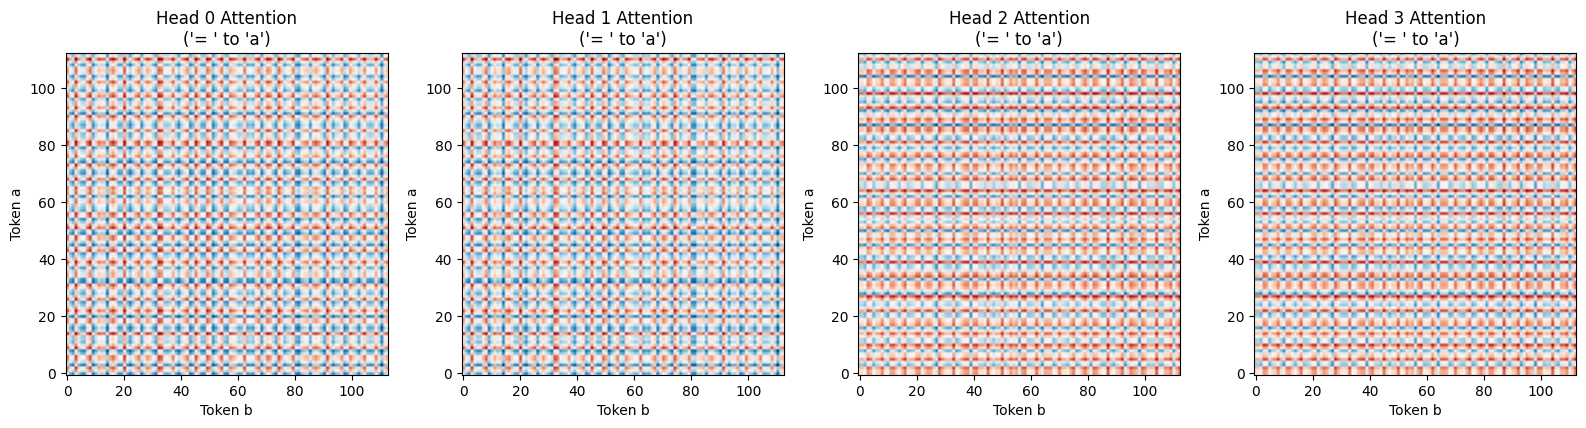

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("="*70)
print("STEP 6: Attention Head Analysis (Specific to Subtraction Prompt)")
print("="*70)

model_subtraction.eval()
with torch.no_grad():

    a_all = torch.arange(P).unsqueeze(1).repeat(1, P).flatten()
    b_all = torch.arange(P).unsqueeze(0).repeat(P, 1).flatten()
    equals_all = torch.full((P*P,), P)
    full_input = torch.stack([a_all, b_all, equals_all], dim=1).to(device)

    _, cache = model_subtraction.run_with_cache(full_input)

    attn_patterns = cache['blocks.0.attn.hook_pattern']

    attn_to_a = attn_patterns[:, :, 2, 0]

n_heads = attn_to_a.shape[1]
attn_grids = attn_to_a.reshape(P, P, n_heads).cpu().numpy()

print("\nCorrelating Attention Patterns with cos(k(a-b)):")
print(f"{'Head':<5} | {'Best Freq (k)':<15} | {'Correlation':<12} | {'Interpretation'}")
print("-" * 65)

for h in range(n_heads):

    attn_surface = attn_grids[:, :, h].flatten()

    best_corr = 0
    best_k = -1

    for k in range(1, P//2):
        w_k = 2 * np.pi * k / P

        target_cos = np.cos(w_k * (a_grid.cpu().numpy().flatten() - b_grid.cpu().numpy().flatten()))

        corr = np.corrcoef(attn_surface, target_cos)[0, 1]

        if abs(corr) > abs(best_corr):
            best_corr = corr
            best_k = k

    interp = "Subtracting Head" if best_corr > 0.5 else "Other/Polysemantic"

    print(f"{h:<5} | {best_k:<15} | {best_corr:<12.4f} | {interp}")

fig, axes = plt.subplots(1, n_heads, figsize=(4*n_heads, 4))
if n_heads == 1: axes = [axes]

for h in range(n_heads):
    im = axes[h].imshow(attn_grids[:, :, h], cmap='RdBu_r', origin='lower')
    axes[h].set_title(f"Head {h} Attention\n('= ' to 'a')")
    axes[h].set_xlabel("Token b")
    axes[h].set_ylabel("Token a")

plt.tight_layout()
plt.show()


### Subtraction embedding spectrum

Rank the Fourier components of the subtraction embeddings and compare the dominant frequencies with those in the neuron–logit map. Frequencies 27 and 46 appear in both analyses.


In [ ]:
import torch
import numpy as np
from scipy.fft import fft
import matplotlib.pyplot as plt

print("="*70)
print("FOURIER ANALYSIS OF EMBEDDING MATRIX (W_E) - SUBTRACTION MODEL")
print("="*70)

W_E = model_subtraction.embed.W_E[:P, :].detach().cpu().numpy()

print(f"\nW_E shape: {W_E.shape} = (P, d_model) = ({P}, {W_E.shape[1]})")

fft_W_E = fft(W_E, axis=0)

cos_norms = np.linalg.norm(np.real(fft_W_E), axis=1)
sin_norms = np.linalg.norm(np.imag(fft_W_E), axis=1)

n_freqs = P // 2 + 1
combined_norms = np.sqrt(cos_norms**2 + sin_norms**2)
top_5_indices = np.argsort(combined_norms[1:n_freqs])[-5:][::-1] + 1

print(f"\nKey frequencies from W_E (threshold-based): {top_5_indices.tolist()}")

print(f"\nTop 5 frequencies from W_E by norm:")
for i, k in enumerate(top_5_indices, 1):
    print(f"    {i}. Frequency {k}: norm = {combined_norms[k]:.4f}")

plt.figure(figsize=(14, 6))

frequencies = np.arange(n_freqs)

plt.plot(frequencies, cos_norms[:n_freqs], 'r-', linewidth=2, label='cos', alpha=0.8)

plt.plot(frequencies, sin_norms[:n_freqs], 'b-', linewidth=2, label='sin', alpha=0.8)

for k in top_5_indices:
    plt.axvline(k, color='gray', linestyle='--', alpha=0.5)
    plt.text(k, max(cos_norms[k], sin_norms[k]) + 5, str(k),
            ha='center', fontsize=10, fontweight='bold')

plt.xlabel('Frequency k', fontsize=12, fontweight='bold')
plt.ylabel('Norm of Fourier Component', fontsize=12, fontweight='bold')
plt.title('Fourier Components of Embedding Matrix',
         fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.xlim(0, n_freqs-1)
plt.tight_layout()

plt.savefig('subtraction_W_E_fourier.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("=== Consensus Key Frequencies ===")
W_E_top5 = set(top_5_indices.tolist())
W_L_top5 = set(key_frequencies)
consensus = sorted(W_E_top5 & W_L_top5)
print(f"Appearing in both W_E and W_L (top 5): {consensus}")
print("="*70)


FOURIER ANALYSIS OF EMBEDDING MATRIX (W_E) - SUBTRACTION MODEL

W_E shape: (113, 128) = (P, d_model) = (113, 128)

Key frequencies from W_E (threshold-based): [27, 46, 13, 8, 48]

Top 5 frequencies from W_E by norm:
    1. Frequency 27: norm = 64.2076
    2. Frequency 46: norm = 62.8863
    3. Frequency 13: norm = 1.4817
    4. Frequency 8: norm = 1.4694
    5. Frequency 48: norm = 1.4217




=== Consensus Key Frequencies ===
Appearing in both W_E and W_L (top 5): [27, 46]


## Findings

The addition model concentrates its learned representations in a small set of Fourier frequencies. Removing frequencies 7, 15, and 19 reduces test accuracy from 100% to 0.88%, while retaining those frequencies together with the DC component preserves 100% accuracy.

The subtraction model develops dominant components at frequencies 27 and 46. Its activation projections reveal trigonometric structure associated with the input difference. A cosine-based logit approximation preserves 100% test accuracy while explaining 50.29% of the variation in the model's logits.

Together, these experiments connect learned weight structure, internal activations, and prediction behavior through Fourier analysis and targeted interventions.

## Reference

Neel Nanda, Lawrence Chan, Tom Lieberum, Jess Smith, and Jacob Steinhardt. 2023. *Progress measures for grokking via mechanistic interpretability*. ICLR 2023. https://arxiv.org/abs/2301.05217
